# Pitfall 3 — Overfitting / parameter mining

> *Torture the data long enough and it will confess to anything.*

The first two pitfalls leaked information from the future: tomorrow's return (Day 2) or
tomorrow's list of survivors (Day 3). This one is subtler. **Every single backtest in this notebook
is honest.** The engine runs with `lag=1`, on real data, with costs. The leak is in the
*research process*: we try many versions of a strategy, then report the one that happened to look
best on the same data we used to choose it.

Same three acts:

1. **The cheat** — grid-search a moving-average strategy over 499 parameter pairs and report the winner.
2. **The reveal**, in two layers:
   (a) out-of-sample, the winner's edge disappears;
   (b) multiple comparisons: the best of 499 noisy numbers is high almost by construction.
3. **The fix** — evaluate the *process* honestly with walk-forward testing, and compare.

The engine (`src/backtest.py`) is unchanged. The strategy and a fast grid evaluator live in a new
module, `src/grid.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

sys.path.insert(0, str(Path.cwd().parent / "src"))
from data import load_prices
from backtest import run_backtest, sharpe_ratio, max_drawdown, TRADING_DAYS
from grid import ma_crossover, grid_sharpe

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 110


def stats(returns: pd.Series) -> pd.Series:
    # Metrics on a daily return stream, using the engine's own Sharpe / drawdown functions.
    equity = (1.0 + returns).cumprod()
    return pd.Series({
        "Sharpe": sharpe_ratio(returns),
        "CAGR": equity.iloc[-1] ** (TRADING_DAYS / len(equity)) - 1.0,
        "MaxDrawdown": max_drawdown(equity),
    })


FMT = {"Sharpe": "{:.2f}", "CAGR": "{:.1%}", "MaxDrawdown": "{:.1%}"}


def plain_log_axis(ax):
    # log scale, but label ticks as 1, 2, 3 ... instead of 2×10⁰
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:g}"))
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())

## Data

Daily adjusted closes for **SPY**, 2005-01-01 → 2024-12-31, from `yfinance` (cached). That's 20 years,
twice the window of Day 2, because the honest version of this experiment needs room to
re-train and test year after year. It includes the 2008 financial crisis, the 2020 COVID
crash and the 2022 bear market.

In [2]:
START, END = "2005-01-01", "2024-12-31"
COST_BPS = 1.0

px = load_prices("SPY", start=START, end=END)["Close"]
years = px.index.year
print(f"{len(px)} trading days: {px.index[0].date()} → {px.index[-1].date()}")

5032 trading days: 2005-01-03 → 2024-12-30


## The strategy: a moving-average trend filter

The textbook trend-following rule, with two knobs:

> At each close, compare a **fast** moving average of SPY to a **slow** one.
> If fast > slow, hold SPY tomorrow. Otherwise, sit in cash.

The rule is look-ahead free: both averages use prices up to today's close, and the engine pays
the position on tomorrow's return (`lag=1`). The only open question is which windows to use, so
we search all of them:

- fast window ∈ {5, 10, …, 100} (20 values)
- slow window ∈ {20, 30, …, 300} (29 values)
- keep only fast < slow → **499 parameter pairs**

To run the grid hundreds of times (we'll need that later), `grid.grid_sharpe` evaluates all pairs
with numpy instead of calling `run_backtest` 499 times. First, check that it gives the same
answer as the engine:

In [3]:
FASTS = list(range(5, 105, 5))
SLOWS = list(range(20, 310, 10))

full_grid = grid_sharpe(px, FASTS, SLOWS, COST_BPS)
print("parameter pairs tested:", int(full_grid.count().sum()))

for f, s in [(10, 50), (45, 160), (5, 300)]:
    engine = run_backtest(px, ma_crossover(px, f, s), cost_bps=COST_BPS, lag=1).sharpe
    assert np.isclose(full_grid.loc[f, s], engine), (f, s)
print("grid_sharpe matches run_backtest ✓")

parameter pairs tested: 499
grid_sharpe matches run_backtest ✓


---
# Act 1 — The cheat

Search all 499 pairs on the full 2005–2024 history, take the one with the highest Sharpe,
and report it next to buy-and-hold.

In [4]:
best_full = full_grid.stack().idxmax()
print("best parameters on 2005–2024 (fast, slow):", best_full)

cheat_bt = run_backtest(px, ma_crossover(px, *best_full), cost_bps=COST_BPS, lag=1)
bh_bt = run_backtest(px, pd.Series(1.0, index=px.index), cost_bps=COST_BPS, lag=1)

pd.DataFrame({
    f"MA {best_full[0]}/{best_full[1]} (optimised)": stats(cheat_bt.returns),
    "Buy & hold SPY": stats(bh_bt.returns),
}).T.style.format(FMT)

best parameters on 2005–2024 (fast, slow): (10, 80)


,Sharpe,CAGR,MaxDrawdown
MA 10/80 (optimised),0.82,9.0%,-20.4%
Buy & hold SPY,0.61,10.3%,-55.2%


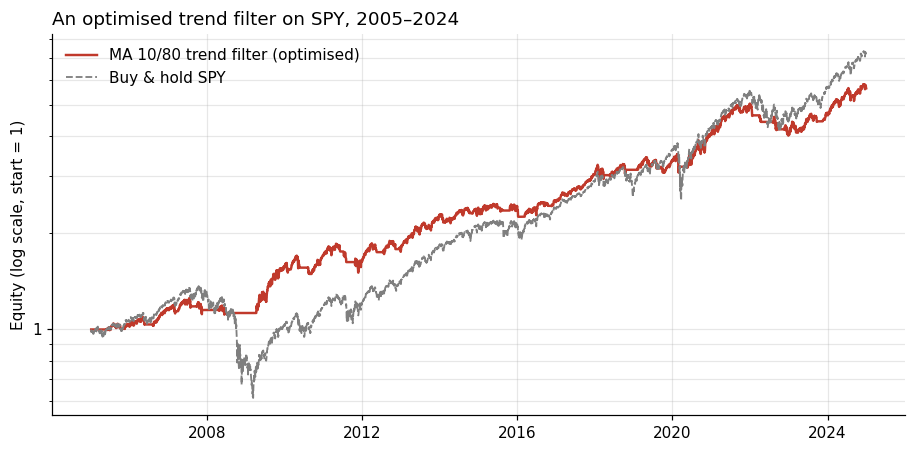

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cheat_bt.equity, color="#c0392b", lw=1.6, label=f"MA {best_full[0]}/{best_full[1]} trend filter (optimised)")
ax.plot(bh_bt.equity, color="#7f7f7f", lw=1.2, ls="--", label="Buy & hold SPY")
ax.set_yscale("log")
plain_log_axis(ax)
ax.set_title("An optimised trend filter on SPY, 2005–2024", loc="left", fontsize=12)
ax.set_ylabel("Equity (log scale, start = 1)")
ax.legend(loc="upper left", frameon=False)
ax.grid(alpha=0.3, which="both")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

This is a convincing pitch. Compared with buy-and-hold, the strategy has a Sharpe about a third
higher, a maximum drawdown cut from −55% to −20%, and it stepped aside during both 2008 and the
2020 crash. Nothing about it looks broken. The Sharpe is under 1, the turnover is low, the logic is
textbook. Unlike Day 2's Sharpe of 13, nothing here sets off an alarm.

---
# Act 2 — The reveal

### What went wrong?

Every backtest in the grid was honest. The problem is the sentence we wrote at the end:
*"MA 10/80 has a Sharpe of 0.82."* That number is not the result of one experiment. It is the
**maximum of 499 experiments**, chosen by looking at the same 20 years it is reported on. The choice
`(10, 80)` was made with 2024's knowledge of how every pair performed from 2005 onwards, which is
another form of look-ahead. This time the future data leaks into the **parameters**, not into the
signal.

Two questions expose it:

- **(a)** If we had picked the parameters *without* seeing the evaluation period, would they still work?
- **(b)** How high would the best of 499 tries be even if none of them had any real skill?

## (a) Out-of-sample testing

### A simple train / test split

Split the history in half. Search the grid on **2005–2014 only**, pick the winner, then evaluate
that single choice on **2015–2024**, data it has never seen.

In [6]:
n_train = int((years < 2015).sum())
train_grid = grid_sharpe(px, FASTS, SLOWS, COST_BPS, eval_slice=slice(0, n_train))
test_grid = grid_sharpe(px, FASTS, SLOWS, COST_BPS, eval_slice=slice(n_train, None))

best_train = train_grid.stack().idxmax()
bh_train = sharpe_ratio(bh_bt.returns.iloc[:n_train])
bh_test = sharpe_ratio(run_backtest(px.iloc[n_train:], pd.Series(1.0, index=px.index[n_train:]), COST_BPS).returns)

split = pd.DataFrame({
    "Train 2005–2014 (in-sample)": [train_grid.loc[best_train], train_grid.stack().median(), bh_train],
    "Test 2015–2024 (out-of-sample)": [test_grid.loc[best_train], test_grid.stack().median(), bh_test],
}, index=[f"Best-in-train MA {best_train[0]}/{best_train[1]}", "Median of all 499 pairs", "Buy & hold"])
split.style.format("{:.2f}").set_caption("Sharpe ratio")

,Train 2005–2014 (in-sample),Test 2015–2024 (out-of-sample)
Best-in-train MA 45/160,0.96,0.71
Median of all 499 pairs,0.70,0.64
Buy & hold,0.46,0.79


The winner's Sharpe falls by about a quarter as soon as it meets new data, and it ends up **below
plain buy-and-hold**. In-sample it beat the median pair by a wide margin. Out-of-sample, most of
that lead is gone.

The bigger problem is visible when we look at **all** 499 pairs at once. If the in-sample ranking
contained real information, pairs that did well in 2005–2014 should also tend to do well in
2015–2024:

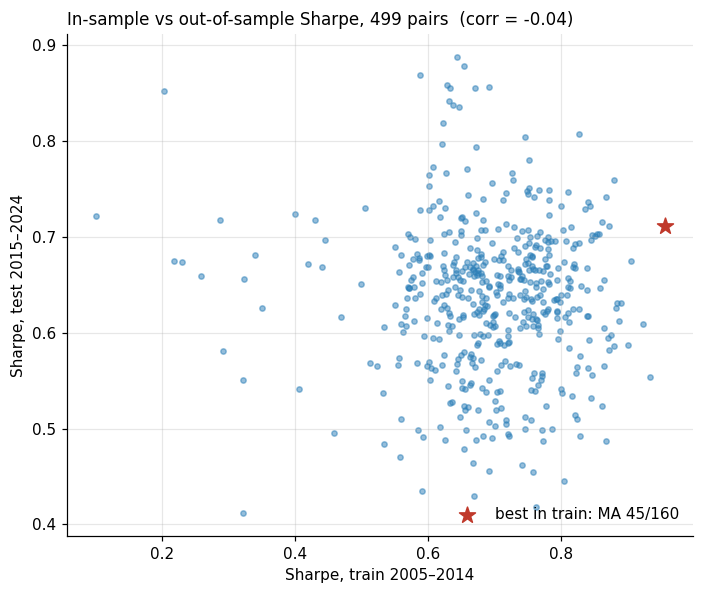

In [7]:
pairs = pd.DataFrame({"train": train_grid.stack(), "test": test_grid.stack()})
rho = pairs["train"].corr(pairs["test"])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(pairs["train"], pairs["test"], s=12, alpha=0.5, color="#2c7fb8")
ax.scatter(*pairs.loc[best_train], s=120, marker="*", color="#c0392b", zorder=3,
           label=f"best in train: MA {best_train[0]}/{best_train[1]}")
ax.set_xlabel("Sharpe, train 2005–2014")
ax.set_ylabel("Sharpe, test 2015–2024")
ax.set_title(f"In-sample vs out-of-sample Sharpe, 499 pairs  (corr = {rho:.2f})", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The correlation is **essentially zero**. Knowing how a parameter pair ranked in-sample tells you
nothing about how it will rank out-of-sample. Picking the top of the in-sample ranking is then
selection on noise: the winner is mostly the pair whose random fluctuations lined up best with
that particular decade.

### Walk-forward: repeat the experiment every year

One split is one data point. A **walk-forward** test repeats the honest procedure many times:
at the end of every year from 2009 to 2023, search the grid on the **trailing five years**, then trade the
winner for **the next year only**. Stitching the 15 out-of-sample years together (2010–2024) gives
the track record you would actually have got by following "always use the best recent parameters".

In [8]:
def walk_forward(px, short=False, train_years=5, first_test_year=2010, last_test_year=2024):
    years = px.index.year
    oos, picks = [], []
    for y in range(first_test_year, last_test_year + 1):
        tr = np.flatnonzero((years >= y - train_years) & (years < y))
        te = np.flatnonzero(years == y)
        g = grid_sharpe(px, FASTS, SLOWS, COST_BPS, short=short, eval_slice=slice(tr[0], tr[-1] + 1)).stack()
        f, s = g.idxmax()
        # start one day early so the first test day earns the position decided at the previous close
        sl = slice(te[0] - 1, te[-1] + 1)
        r = run_backtest(px.iloc[sl], ma_crossover(px, f, s, short=short).iloc[sl], COST_BPS, lag=1).returns.iloc[1:]
        oos.append(r)
        picks.append({"test year": y, "fast": f, "slow": s,
                      "in-sample Sharpe": g.max(), "out-of-sample Sharpe": sharpe_ratio(r)})
    return pd.concat(oos), pd.DataFrame(picks).set_index("test year")


wf_ret, wf_picks = walk_forward(px)
wf_picks.style.format({"in-sample Sharpe": "{:.2f}", "out-of-sample Sharpe": "{:.2f}"})

,fast,slow,in-sample Sharpe,out-of-sample Sharpe
test year,,,,
2010,40,210,1.02,0.14
2011,30,230,0.92,-0.55
2012,50,90,0.65,0.81
2013,50,90,0.81,2.16
2014,40,150,1.35,1.18
2015,45,90,1.20,0.06
2016,50,90,1.08,-0.55
2017,20,30,1.19,2.60
2018,40,50,1.44,0.32


Two things stand out:

- **The "optimal" parameters jump around**, from 40/210 to 20/30 to 5/20. If the best
  parameters reflected something stable about the market, they wouldn't change this much from one
  five-year window to the next.
- **The optimiser over-promises.** The chosen pair's in-sample Sharpe is always flattering
  (every year above 0.6), while its out-of-sample Sharpe swings from about −2 to +2.6. On average
  it delivers far less than it promised:

In [9]:
print(f"mean in-sample Sharpe of the chosen pair:   {wf_picks['in-sample Sharpe'].mean():.2f}")
print(f"mean out-of-sample Sharpe of the same pair: {wf_picks['out-of-sample Sharpe'].mean():.2f}")
print(f"years where out-of-sample < in-sample:      {(wf_picks['out-of-sample Sharpe'] < wf_picks['in-sample Sharpe']).sum()} / {len(wf_picks)}")

mean in-sample Sharpe of the chosen pair:   1.10
mean out-of-sample Sharpe of the same pair: 0.69
years where out-of-sample < in-sample:      9 / 15


The same procedure on the **long/short** version of the strategy (short instead of cash when
fast < slow) is a starker example. That version has more variation across parameters, so there's
more to overfit:

In [10]:
grid_ls = grid_sharpe(px, FASTS, SLOWS, COST_BPS, short=True)
best_ls = grid_ls.stack().idxmax()
wf_ls_ret, _ = walk_forward(px, short=True)
pd.DataFrame({
    "Full-sample best (in-sample)": [f"{best_ls[0]}/{best_ls[1]}", grid_ls.loc[best_ls]],
    "Walk-forward 2010–2024 (out-of-sample)": ["re-chosen yearly", sharpe_ratio(wf_ls_ret)],
}, index=["parameters", "Sharpe"]).T

,parameters,Sharpe
Full-sample best (in-sample),45/160,0.5084
Walk-forward 2010–2024 (out-of-sample),re-chosen yearly,-0.0920


For the long/short version, the in-sample optimum is positive and the walk-forward result is
**negative**. The edge doesn't just shrink, it flips sign.

## (b) Multiple comparisons: the best of 499 is high by construction

### Where the winner sits in the grid

Below is the distribution of full-sample Sharpe ratios across all 499 pairs. The reported result is
the right-most bar.

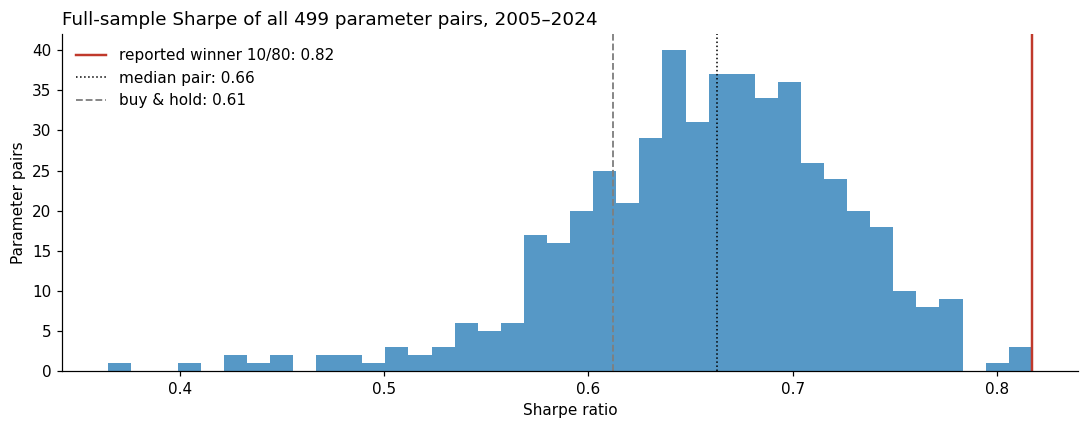

winner − median: 0.15   vs   standard error of one Sharpe estimate over 20 years: 0.26


In [11]:
sh = full_grid.stack()
T_years = len(px) / TRADING_DAYS
se = np.sqrt((1 + sh.max() ** 2 / 2) / T_years)  # Lo (2002): standard error of an annualised Sharpe

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sh, bins=40, color="#2c7fb8", alpha=0.8)
ax.axvline(sh.max(), color="#c0392b", lw=1.6, label=f"reported winner {best_full[0]}/{best_full[1]}: {sh.max():.2f}")
ax.axvline(sh.median(), color="black", lw=1.0, ls=":", label=f"median pair: {sh.median():.2f}")
ax.axvline(stats(bh_bt.returns)["Sharpe"], color="#7f7f7f", lw=1.2, ls="--",
           label=f"buy & hold: {stats(bh_bt.returns)['Sharpe']:.2f}")
ax.set_title("Full-sample Sharpe of all 499 parameter pairs, 2005–2024", loc="left", fontsize=12)
ax.set_xlabel("Sharpe ratio")
ax.set_ylabel("Parameter pairs")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"winner − median: {sh.max() - sh.median():.2f}   vs   standard error of one Sharpe estimate over {T_years:.0f} years: {se:.2f}")

The gap between the winner and a typical pair is **smaller than the statistical uncertainty of a
single Sharpe estimate**. Over 20 years, a Sharpe ratio is only measured to within about ±0.25
(one standard error is ≈ 0.26). A spread of a few tenths across 499 pairs is what noise alone produces.

### Data-snooping intuition: more tries → a higher maximum, even with zero skill

Suppose none of the strategies has any edge at all: every true Sharpe is exactly zero. Each
*estimated* Sharpe over $T$ years is then roughly normal with mean 0 and standard deviation
$1/\sqrt{T}$. Now try $N$ of them and keep the best. How high does the best one look?

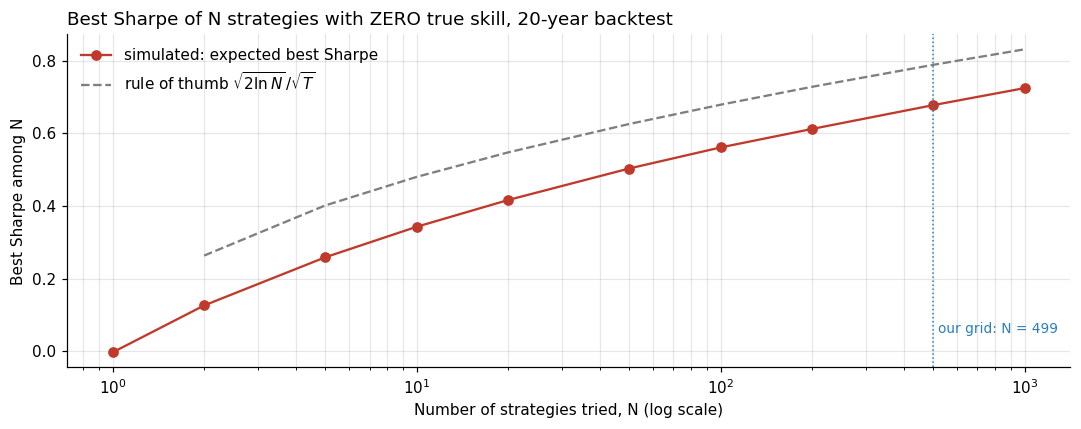

expected best Sharpe of 500 zero-skill strategies over 20 years: 0.68


In [12]:
rng = np.random.default_rng(0)
Ns = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
noise_sharpes = rng.standard_normal((4000, Ns.max())) / np.sqrt(T_years)   # 4000 repeats of N zero-skill strategies
expected_max = np.array([noise_sharpes[:, :n].max(axis=1).mean() for n in Ns])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(Ns, expected_max, "o-", color="#c0392b", label="simulated: expected best Sharpe")
ax.plot(Ns[1:], np.sqrt(2 * np.log(Ns[1:])) / np.sqrt(T_years), ls="--", color="#7f7f7f",
        label=r"rule of thumb $\sqrt{2\ln N}\,/\sqrt{T}$")
ax.axvline(499, color="#2c7fb8", lw=1, ls=":")
ax.text(520, 0.05, "our grid: N = 499", color="#2c7fb8", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Number of strategies tried, N (log scale)")
ax.set_ylabel("Best Sharpe among N")
ax.set_title(f"Best Sharpe of N strategies with ZERO true skill, {T_years:.0f}-year backtest", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.3, which="both")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"expected best Sharpe of 500 zero-skill strategies over {T_years:.0f} years: {expected_max[Ns == 500][0]:.2f}")

With 500 independent tries and **no skill at all**, the best one shows a Sharpe of around 0.7
over 20 years on average. That's close to what our "optimised" strategy reports, and well above
buy-and-hold.

Our 499 pairs are not independent: neighbouring windows produce very similar signals, so the
*effective* number of independent trials is smaller and the inflation is weaker. The direction
doesn't change, though. **Every additional parameter you try raises the bar a result has to
clear before it means anything**, and that bar is invisible unless you report how many things you
tried.

### A permutation test on the actual grid

The noise simulation is generic. For a test specific to *this* grid and *this* data, we can
**shuffle the order of SPY's daily returns**. That keeps the same returns (same average, same
volatility, same crashes) but destroys any trend a moving average could exploit. Then rerun all
499 pairs and record how much the best one beats buy-and-hold on that shuffled history. Repeat 200
times.

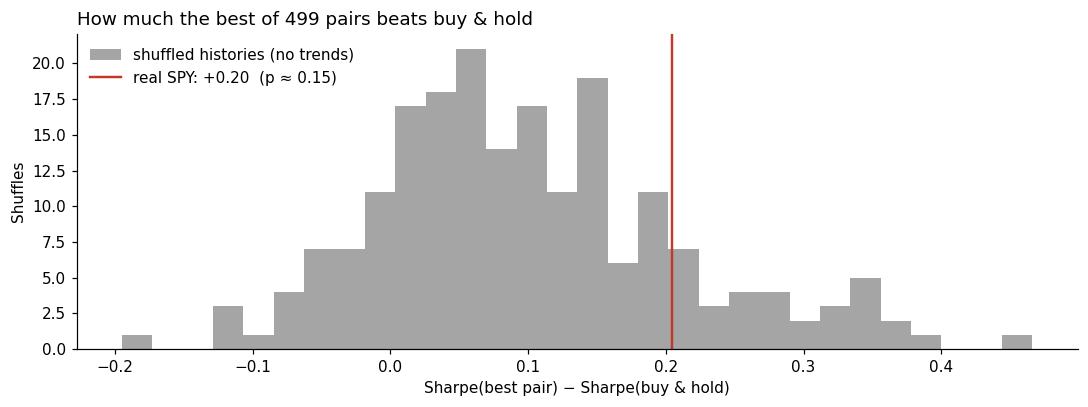

p-value of the winner's edge over buy & hold: 0.15
median pair minus B&H — real: +0.05,  shuffled (median of 200): -0.14


In [13]:
def best_minus_bh(prices):
    r = prices.pct_change().fillna(0.0)
    g = grid_sharpe(prices, FASTS, SLOWS, COST_BPS).stack()
    return g.max() - sharpe_ratio(r.iloc[1:]), g.median() - sharpe_ratio(r.iloc[1:])

ret = px.pct_change().fillna(0.0).to_numpy()
rng = np.random.default_rng(1)
null = []
for _ in range(200):
    shuffled = np.r_[0.0, rng.permutation(ret[1:])]
    null.append(best_minus_bh(pd.Series(px.iloc[0] * np.cumprod(1 + shuffled), index=px.index)))
null = pd.DataFrame(null, columns=["best − B&H", "median − B&H"])

actual_best, actual_median = best_minus_bh(px)
p_value = (null["best − B&H"] >= actual_best).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(null["best − B&H"], bins=30, color="#7f7f7f", alpha=0.7, label="shuffled histories (no trends)")
ax.axvline(actual_best, color="#c0392b", lw=1.6, label=f"real SPY: {actual_best:+.2f}  (p ≈ {p_value:.2f})")
ax.set_title("How much the best of 499 pairs beats buy & hold", loc="left", fontsize=12)
ax.set_xlabel("Sharpe(best pair) − Sharpe(buy & hold)")
ax.set_ylabel("Shuffles")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"p-value of the winner's edge over buy & hold: {p_value:.2f}")
print(f"median pair minus B&H — real: {actual_median:+.2f},  shuffled (median of 200): {null['median − B&H'].median():+.2f}")

This result has some nuance:

- **The winner's edge is not statistically distinguishable from luck.** In roughly 15% of shuffles,
  a history with *no* trends at all produces a "best pair" that beats buy-and-hold by as much as
  MA 10/80 does on real SPY. By the usual 5% standard, the headline result proves nothing.
- **The family as a whole may have something real.** On real data the *median* pair does
  noticeably better relative to buy-and-hold than on shuffled data. That's consistent with the
  known idea that trend filters help by sidestepping high-volatility crashes. (Shuffling destroys
  volatility clustering as well as trends, so this test can't tell which of the two is helping.)

So the honest statement is something like *"MA trend filters on SPY may reduce drawdowns, and the
whole family shows it."* The dishonest one is *"MA 10/80 specifically has a Sharpe of 0.82."*
The difference between those two sentences is the overfitting.

### Spikes vs plateaus: the parameter heatmap

A robust effect should show up as a **plateau**: a broad region of similar parameters that all
work. An overfit result shows up as an isolated **spike**, with the optimum surrounded by
noticeably worse neighbours, or one that moves when the data changes.

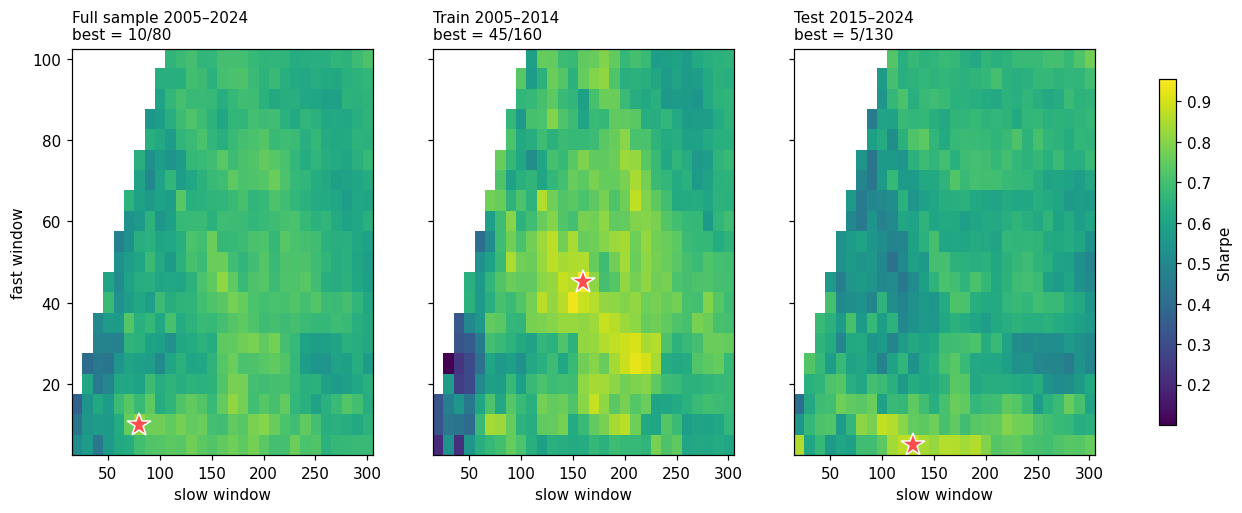

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
vmin = min(g.min().min() for g in (full_grid, train_grid, test_grid))
vmax = max(g.max().max() for g in (full_grid, train_grid, test_grid))
panels = [(full_grid, best_full, "Full sample 2005–2024"),
          (train_grid, best_train, "Train 2005–2014"),
          (test_grid, test_grid.stack().idxmax(), "Test 2015–2024")]
for ax, (g, best, title) in zip(axes, panels):
    im = ax.imshow(g.values, origin="lower", aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax,
                   extent=[SLOWS[0] - 5, SLOWS[-1] + 5, FASTS[0] - 2.5, FASTS[-1] + 2.5])
    ax.plot(best[1], best[0], marker="*", ms=16, color="#ff4d4d", mec="white")
    ax.set_title(f"{title}\nbest = {best[0]}/{best[1]}", loc="left", fontsize=10)
    ax.set_xlabel("slow window")
axes[0].set_ylabel("fast window")
fig.colorbar(im, ax=axes, shrink=0.85, label="Sharpe")
plt.show()

In [15]:
def neighbourhood(g, best, k=1):
    # mean Sharpe of the pairs within ±k grid steps of the best one (excluding itself)
    fi, si = FASTS.index(best[0]), SLOWS.index(best[1])
    block = g.iloc[max(fi - k, 0): fi + k + 1, max(si - k, 0): si + k + 1].stack()
    return block.drop(best).mean()

pd.DataFrame({
    "best pair": [f"{b[0]}/{b[1]}" for _, b, _ in panels],
    "Sharpe at the best pair": [g.loc[b] for g, b, _ in panels],
    "mean of its 8 neighbours": [neighbourhood(g, b) for g, b, _ in panels],
}, index=[t for _, _, t in panels])

,best pair,Sharpe at the best pair,mean of its 8 neighbours
Full sample 2005–2024,10/80,0.8169,0.7148
Train 2005–2014,45/160,0.9552,0.8509
Test 2015–2024,5/130,0.8879,0.8010


The star moves a lot from panel to panel: 10/80 on the full sample, 45/160 in 2005–2014, 5/130 in
2015–2024. In every panel the optimum also sits above the average of its own neighbours.

The middle panel is the most instructive. In 2005–2014 there *is* a broad bright region (fast ≈ 30–50,
slow ≈ 120–230). It looks exactly like the "robust plateau" you're told to look for. In 2015–2024 that
same region is unremarkable, and the bright area has moved to the very fastest windows along the bottom
edge. A plateau protects you against picking a lucky *point*. It doesn't protect you against a lucky
*period*, because the whole regime can change. The only thing that stays stable across all three panels
is the broad, moderately good level of the whole family, which matches what the permutation test
found.

---
# Act 3 — The fix

There's no "correct" parameter to switch to. The fix is to **stop reporting the in-sample
maximum** and instead measure the whole research process, "pick the best recent parameters,
then trade them", on data it hasn't seen. That's exactly what the walk-forward test produced.

Compare the two over the same out-of-sample window (2010–2024):

- **Cheat:** MA 10/80, chosen with full knowledge of 2005–2024, evaluated on 2010–2024
  (part of the data it was chosen on).
- **Honest:** the walk-forward track record, where every year is traded with parameters chosen
  only from the five years before it.
- **Reference:** buy-and-hold SPY.

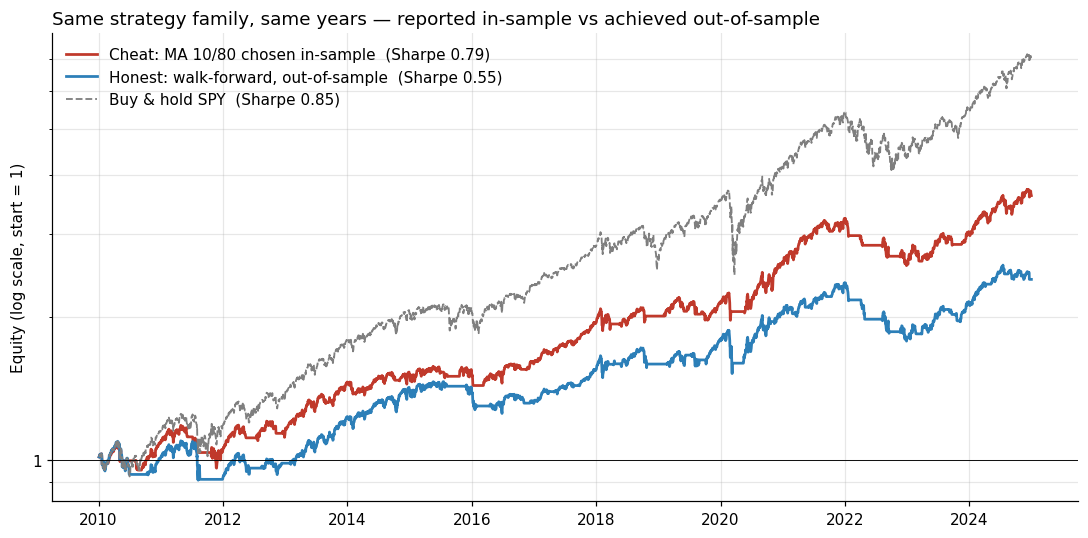

In [16]:
window = wf_ret.index
cheat_w = cheat_bt.returns.loc[window]
bh_w = bh_bt.returns.loc[window]

curves = {
    f"Cheat: MA {best_full[0]}/{best_full[1]} chosen in-sample": (cheat_w, "#c0392b", "-"),
    "Honest: walk-forward, out-of-sample": (wf_ret, "#2c7fb8", "-"),
    "Buy & hold SPY": (bh_w, "#7f7f7f", "--"),
}

fig, ax = plt.subplots(figsize=(10, 5))
for label, (r, color, ls) in curves.items():
    ax.plot((1 + r).cumprod(), color=color, ls=ls, lw=1.8 if ls == "-" else 1.2,
            label=f"{label}  (Sharpe {sharpe_ratio(r):.2f})")
ax.set_yscale("log")
plain_log_axis(ax)
ax.axhline(1.0, color="black", lw=0.6)
ax.set_title("Same strategy family, same years — reported in-sample vs achieved out-of-sample", loc="left", fontsize=12)
ax.set_ylabel("Equity (log scale, start = 1)")
ax.legend(loc="upper left", frameon=False)
ax.grid(alpha=0.3, which="both")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [17]:
comparison = pd.DataFrame({label: stats(r) for label, (r, _, _) in curves.items()}).T
comparison.style.format(FMT).set_caption(f"{window[0].date()} → {window[-1].date()}")

,Sharpe,CAGR,MaxDrawdown
Cheat: MA 10/80 chosen in-sample,0.79,9.0%,-20.4%
"Honest: walk-forward, out-of-sample",0.55,6.0%,-24.6%
Buy & hold SPY,0.85,13.8%,-33.7%


The in-sample winner looks like it roughly matches buy-and-hold's risk-adjusted return with less
pain. The process that actually produces such a winner, applied honestly year by year, **gives a
clearly lower Sharpe than simply holding SPY**. The gap between the red and blue curves is the
overfitting premium: performance that existed only because the parameters were chosen after
seeing the answers.

### How to avoid it in practice

- **Keep a hold-out set and use it once.** Every time you look at test results and go back to
  adjust, the test set becomes part of the training set.
- **Prefer walk-forward / rolling re-estimation** to a single split. It tests the
  *procedure*, which is what you'll actually run live.
- **Count and report your trials.** A Sharpe of 0.8 means something very different after 1 try
  than after 500. The *Deflated Sharpe Ratio* (Bailey & López de Prado, 2014) adjusts a reported
  Sharpe for the number of trials. Harvey, Liu & Zhu (2016) argue that, given how many factors
  have been tried, a new one should need a t-statistic above ~3, not 2.
- **Look for plateaus, not peaks.** Choose a region of parameters that works broadly, and be
  suspicious of an optimum that its neighbours don't support.
- **Fewer knobs.** Every parameter is another dimension to overfit in. If a strategy only works
  with precisely tuned windows, it probably doesn't work.

---
# Takeaways

- **Overfitting is look-ahead bias in the parameters.** Day 2 leaked the future into the signal,
  Day 3 into the universe. Here it leaks into the *choice* of strategy, through the researcher.
- **Each backtest can be honest while the result is not.** Lag, data and costs were all correct.
  The bias came from reporting the maximum of 499 honest backtests.
- **In-sample rank ≠ out-of-sample rank.** Across all pairs the train/test Sharpe correlation was
  about zero, so the winner was chosen on noise.
- **The number to report is the out-of-sample performance of the process.** Here that turns
  "beats buy-and-hold with a third of the drawdown" into "does worse than buy-and-hold".
- **The bar rises with every try.** With 500 zero-skill strategies over 20 years, the best one
  shows a Sharpe of ~0.7 on average. A result has to clear that bar to mean anything.